# Unemployment Analysis in India (Covid-19 Impact)

**Pipeline:** Extract (CSV) -> Clean (Pandas) -> Load (SQLite) -> Query (SQL) -> Visualise (Matplotlib)

**Questions answered**
1. How did the unemployment rate change over time, and what did Covid-19 do to it?
2. Were rural or urban areas hit harder?
3. Which states and regions were affected most?
4. How fast was the recovery?
5. Is there a seasonal pattern?

**Data:** two CSV files in `data/raw/`
- `Unemployment in India.csv`: May 2019 - Jun 2020, state x Rural/Urban x month
- `Unemployment_Rate_upto_11_2020.csv`: Jan 2020 - Oct 2020, state x month, with macro-region

Run this notebook from the project root folder so the `data/raw` path is found.

## 1. Setup

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

# Works whether Jupyter was started in the project root or in a sub-folder
ROOT = Path.cwd() if (Path.cwd() / "data" / "raw").exists() else Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw"
DB_PATH = ROOT / "data" / "unemployment.db"
LOCKDOWN_DAY = pd.Timestamp("2020-03-25")   # national lockdown start in India

print("Project folder:", ROOT)

Project folder: e:\ML_Projects\unemployment-analysis-india


## 2. Extract: load the raw files

`encoding="utf-8-sig"` is used for the first file because it starts with a hidden BOM character that would otherwise corrupt the first column name.

In [2]:
area_raw = pd.read_csv(RAW_DIR / "Unemployment in India.csv", encoding="utf-8-sig")
regional_raw = pd.read_csv(RAW_DIR / "Unemployment_Rate_upto_11_2020.csv")
print("area file:", area_raw.shape, "| regional file:", regional_raw.shape)

area file: (768, 7) | regional file: (267, 9)


In [3]:
area_raw.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [4]:
regional_raw.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


## 3. Inspect: what is wrong with the raw data?

Cleaning should be driven by evidence, so we look for problems first.

In [4]:
print("Column names (note the leading spaces):")
print(area_raw.columns.tolist())
print()
print("Fully blank rows in area file:", area_raw.isnull().all(axis=1).sum())
print("Duplicate rows (after removing blanks):", area_raw.dropna(how="all").duplicated().sum())
print()
print("Regional file columns:", regional_raw.columns.tolist())
print("Frequency values:", regional_raw[" Frequency"].unique())

Column names (note the leading spaces):
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Fully blank rows in area file: 28
Duplicate rows (after removing blanks): 0

Regional file columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']
Frequency values: <StringArray>
[' M']
Length: 1, dtype: str


In [5]:
# Latitude/longitude check: Andhra Pradesh is around latitude 15.9, longitude 79.7
regional_raw[["Region", "longitude", "latitude"]].head(2)

,Region,longitude,latitude
0,Andhra Pradesh,15.9129,79.74
1,Andhra Pradesh,15.9129,79.74


**Problems found**
- Column names have stray spaces; the first file has a hidden BOM character.
- 28 fully blank rows in the first file.
- Dates are text in `dd-mm-yyyy` format.
- The second file has two columns called `Region` (the second is the macro-region: North/South/...).
- In the second file, `longitude` holds latitude values and `latitude` holds longitude values (columns are swapped).
- Frequency is `M` in one file and `Monthly` in the other.

## 4. Transform: clean both files

In [6]:
RENAME = {
    "Region": "region",
    "Date": "date",
    "Frequency": "frequency",
    "Estimated Unemployment Rate (%)": "unemployment_rate",
    "Estimated Employed": "employed",
    "Estimated Labour Participation Rate (%)": "labour_participation",
    "Area": "area",
}

# ---- File 1: state x Rural/Urban ----
area = area_raw.copy()
area.columns = area.columns.str.strip()           # fix stray spaces in headers
area = area.dropna(how="all")                      # remove fully blank rows
area = area.rename(columns=RENAME)
for col in ["region", "frequency", "area"]:
    area[col] = area[col].str.strip()
area["date"] = pd.to_datetime(area["date"].str.strip(), format="%d-%m-%Y")
area = area.drop_duplicates()

print("area:", area.shape)
area.dtypes

area: (740, 7)


region                             str
date                    datetime64[us]
frequency                          str
unemployment_rate              float64
employed                       float64
labour_participation           float64
area                               str
dtype: object

In [8]:
# ---- File 2: state x month with macro-region ----
regional = regional_raw.copy()
regional.columns = regional.columns.str.strip()
# pandas renames the 2nd duplicate 'Region' column to 'Region.1'
regional = regional.rename(columns=RENAME).rename(columns={"Region.1": "macro_region"})
# swap the mislabelled coordinate columns back
regional = regional.rename(columns={"longitude": "latitude", "latitude": "longitude"})
regional["region"] = regional["region"].str.strip()
regional["macro_region"] = regional["macro_region"].str.strip()
regional["frequency"] = regional["frequency"].str.strip().replace({"M": "Monthly"})
regional["date"] = pd.to_datetime(regional["date"].str.strip(), format="%d-%m-%Y")
regional = regional.drop_duplicates()

print("regional:", regional.shape)
regional.head()

regional: (267, 9)


,region,date,frequency,unemployment_rate,employed,labour_participation,macro_region,latitude,longitude
0,Andhra Pradesh,2020-01-31,Monthly,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,2020-02-29,Monthly,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,2020-03-31,Monthly,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,2020-04-30,Monthly,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,2020-05-31,Monthly,17.43,12988845,36.46,South,15.9129,79.74


### Period labels

To measure the Covid effect we label every row:
- `pre_covid`: before March 2020
- `lockdown`: April - May 2020
- `transition`: March 2020 (lockdown started on 25 March) and June 2020 onwards

March is kept separate because only the last days of the month were under lockdown.

In [9]:
def add_period(df):
    df = df.copy()
    conditions = [
        df["date"] < pd.Timestamp("2020-03-01"),
        df["date"].between("2020-04-01", "2020-05-31"),
    ]
    df["period"] = np.select(conditions, ["pre_covid", "lockdown"], default="transition")
    return df

area = add_period(area).sort_values(["region", "area", "date"]).reset_index(drop=True)
regional = add_period(regional).sort_values(["region", "date"]).reset_index(drop=True)
area["period"].value_counts()

period
pre_covid     536
transition    102
lockdown      102
Name: count, dtype: int64

## 5. Validate: fail loudly if the data breaks expectations

In [10]:
def validate(df, name):
    assert df.isnull().sum().sum() == 0, f"{name}: null values remain"
    assert df["unemployment_rate"].between(0, 100).all(), f"{name}: rate outside 0-100"
    assert (df["frequency"] == "Monthly").all(), f"{name}: unexpected frequency"
    print(f"{name}: OK ({len(df)} rows)")

validate(area, "area")
validate(regional, "regional")

area: OK (740 rows)
regional: OK (267 rows)


## 6. Load: write the clean data to SQLite

Why SQLite: cleaning happens once, and every later question is answered with SQL on the stored tables. This is the same Extract -> Transform -> Load -> Query pattern used in data engineering, just at small scale.

In [11]:
with sqlite3.connect(DB_PATH) as conn:
    for name, df in {"unemployment_area": area, "unemployment_regional_2020": regional}.items():
        out = df.copy()
        out["date"] = out["date"].dt.strftime("%Y-%m-%d")   # SQLite stores dates as text
        out.to_sql(name, conn, if_exists="replace", index=False)

    print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn))
    print(pd.read_sql("SELECT COUNT(*) AS rows_in_area FROM unemployment_area", conn))

                         name
0           unemployment_area
1  unemployment_regional_2020
   rows_in_area
0           740


## 7. Analysis with SQL

Note: all averages below are simple (unweighted) means of state-level rates, **not** an official national rate.

In [12]:
def query(sql):
    with sqlite3.connect(DB_PATH) as conn:
        return pd.read_sql(sql, conn)

def to_date(month_series):
    return pd.to_datetime(month_series + "-01")

### 7.1 Monthly trend and the Covid spike

In [13]:
monthly = query('''
    SELECT substr(date, 1, 7) AS month,
           ROUND(AVG(unemployment_rate), 2) AS avg_unemployment_rate
    FROM unemployment_area
    GROUP BY month ORDER BY month
''')
monthly

,month,avg_unemployment_rate
0,2019-05,8.87
1,2019-06,9.30
2,2019-07,9.03
3,2019-08,9.64
4,2019-09,9.05
5,2019-10,9.90
6,2019-11,9.87
7,2019-12,9.50
8,2020-01,9.95
9,2020-02,9.96


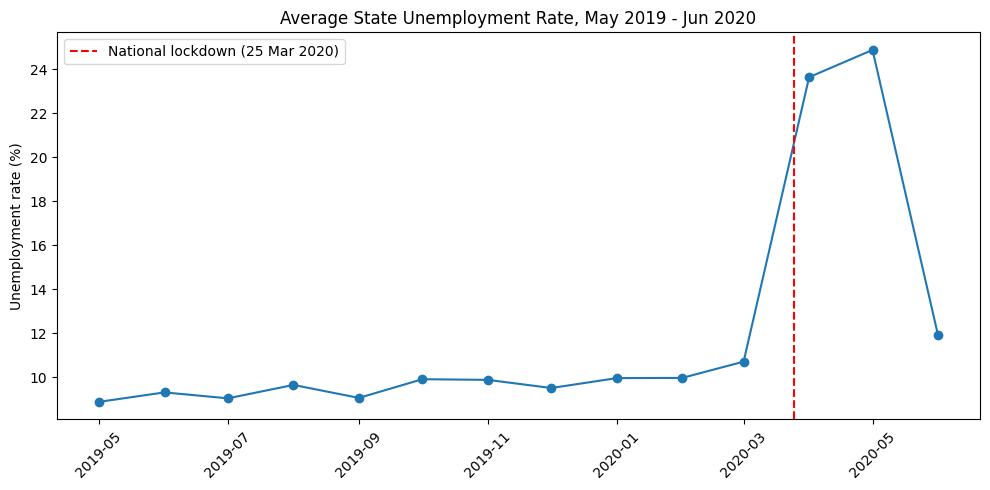

In [14]:
plt.figure(figsize=(10, 5))
plt.plot(to_date(monthly["month"]), monthly["avg_unemployment_rate"], marker="o")
plt.axvline(LOCKDOWN_DAY, color="red", linestyle="--", label="National lockdown (25 Mar 2020)")
plt.title("Average State Unemployment Rate, May 2019 - Jun 2020")
plt.ylabel("Unemployment rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Finding:** the average rate was around 9.5% before Covid, then jumped to 23.6% in April 2020 and 24.9% in May 2020, the lockdown months.

### 7.2 Rural vs urban

In [15]:
rural_urban = query('''
    SELECT substr(date, 1, 7) AS month, area,
           ROUND(AVG(unemployment_rate), 2) AS avg_unemployment_rate
    FROM unemployment_area
    GROUP BY month, area ORDER BY month, area
''')
rural_urban.pivot(index="month", columns="area", values="avg_unemployment_rate")

area,Rural,Urban
month,,
2019-05,7.07,10.55
2019-06,8.20,10.33
2019-07,7.74,10.23
2019-08,8.50,10.73
2019-09,7.04,10.92
2019-10,9.05,10.72
2019-11,8.43,11.25
2019-12,8.23,10.63
2020-01,7.84,11.98


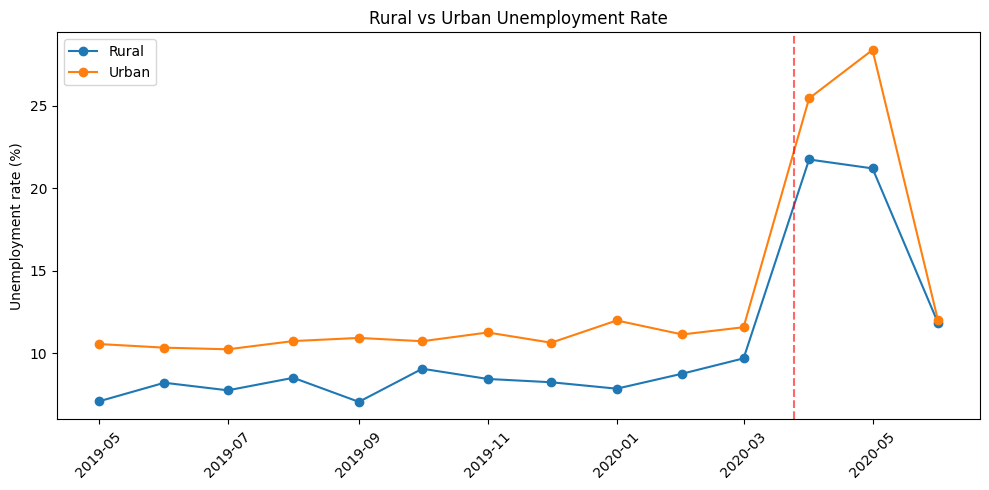

In [16]:
plt.figure(figsize=(10, 5))
for name, grp in rural_urban.groupby("area"):
    plt.plot(to_date(grp["month"]), grp["avg_unemployment_rate"], marker="o", label=name)
plt.axvline(LOCKDOWN_DAY, color="red", linestyle="--", alpha=0.6)
plt.title("Rural vs Urban Unemployment Rate")
plt.ylabel("Unemployment rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
query('''
    SELECT area, period, ROUND(AVG(unemployment_rate), 2) AS avg_rate
    FROM unemployment_area
    GROUP BY area, period
    ORDER BY area, period
''')

,area,period,avg_rate
0,Rural,lockdown,21.48
1,Rural,pre_covid,8.09
2,Rural,transition,10.78
3,Urban,lockdown,26.93
4,Urban,pre_covid,10.84
5,Urban,transition,11.77


**Finding:** urban areas were hit harder. Rural unemployment went from 8.1% to 21.5% (+13.4 points); urban went from 10.8% to 26.9% (+16.1 points). In May 2020 the gap was widest: 28.4% urban vs 21.2% rural.

### 7.3 Which states were hit hardest?

In [18]:
state_impact = query('''
    SELECT region,
           ROUND(AVG(CASE WHEN period = 'pre_covid' THEN unemployment_rate END), 2) AS pre_covid,
           ROUND(AVG(CASE WHEN period = 'lockdown'  THEN unemployment_rate END), 2) AS lockdown,
           ROUND(AVG(CASE WHEN period = 'lockdown'  THEN unemployment_rate END)
               - AVG(CASE WHEN period = 'pre_covid' THEN unemployment_rate END), 2) AS increase
    FROM unemployment_area
    GROUP BY region
    HAVING increase IS NOT NULL
    ORDER BY increase DESC
''')
state_impact.head(10)

,region,pre_covid,lockdown,increase
0,Puducherry,1.59,75.42,73.82
1,Jharkhand,14.28,57.12,42.84
2,Tamil Nadu,2.84,40.85,38.02
3,Bihar,13.83,47.25,33.41
4,Karnataka,3.23,24.47,21.24
5,Haryana,22.94,40.30,17.36
6,Madhya Pradesh,4.74,21.85,17.11
7,Andhra Pradesh,5.04,21.99,16.95
8,Telangana,4.66,21.40,16.74
9,Kerala,6.99,21.45,14.46


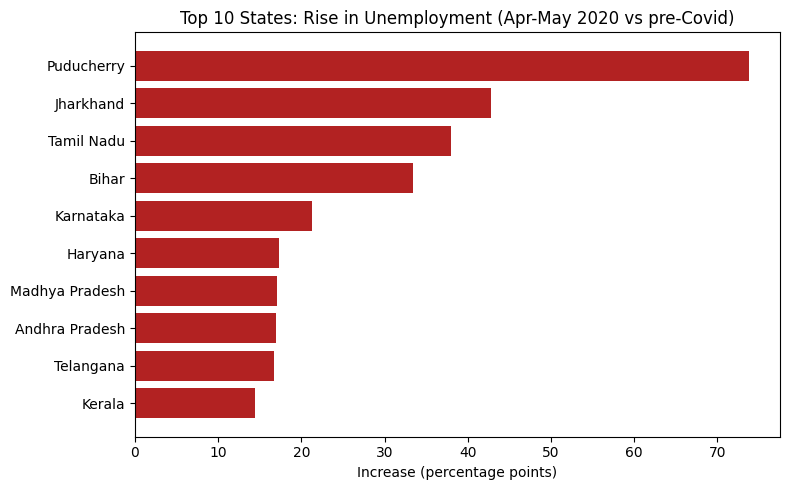

In [19]:
top = state_impact.head(10).sort_values("increase")
plt.figure(figsize=(8, 5))
plt.barh(top["region"], top["increase"], color="firebrick")
plt.title("Top 10 States: Rise in Unemployment (Apr-May 2020 vs pre-Covid)")
plt.xlabel("Increase (percentage points)")
plt.tight_layout()
plt.show()

**Finding:** Puducherry (+73.8 points), Jharkhand (+42.8), Tamil Nadu (+38.0), Bihar (+33.4) and Karnataka (+21.2) had the largest increases. Jammu & Kashmir and Tripura showed no rise. Chandigarh has no lockdown-period data, so it is excluded.

In [20]:
state_impact.tail(5)

,region,pre_covid,lockdown,increase
22,Assam,6.37,9.51,3.13
23,Sikkim,6.26,8.51,2.25
24,Himachal Pradesh,19.13,20.12,0.99
25,Tripura,29.01,27.50,-1.51
26,Jammu & Kashmir,17.22,7.59,-9.63


### 7.4 Recovery through 2020 (second file)

In [21]:
recovery = query('''
    SELECT substr(date, 1, 7) AS month,
           ROUND(AVG(unemployment_rate), 2) AS avg_unemployment_rate
    FROM unemployment_regional_2020
    GROUP BY month ORDER BY month
''')
recovery

,month,avg_unemployment_rate
0,2020-01,9.20
1,2020-02,9.27
2,2020-03,10.78
3,2020-04,22.24
4,2020-05,23.24
5,2020-06,10.91
6,2020-07,9.83
7,2020-08,10.31
8,2020-09,8.71
9,2020-10,8.03


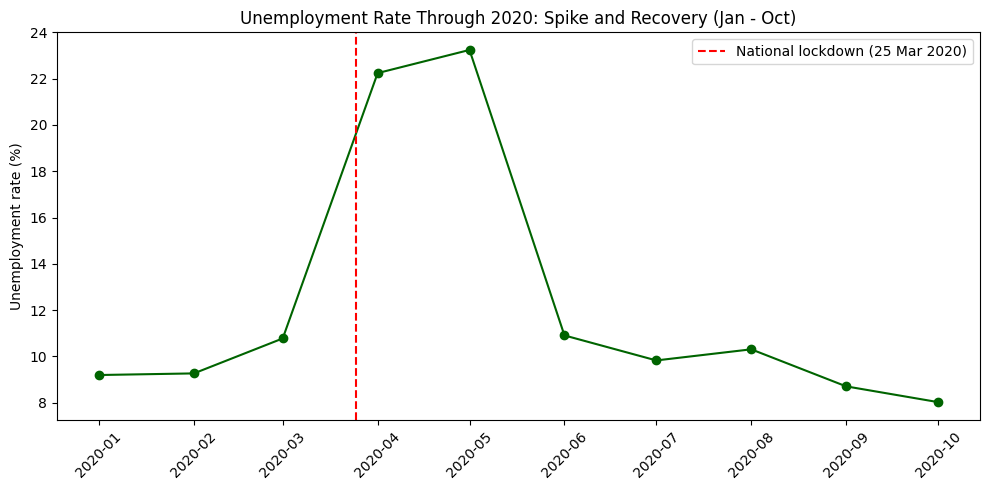

In [22]:
plt.figure(figsize=(10, 5))
plt.plot(to_date(recovery["month"]), recovery["avg_unemployment_rate"], marker="o", color="darkgreen")
plt.axvline(LOCKDOWN_DAY, color="red", linestyle="--", label="National lockdown (25 Mar 2020)")
plt.title("Unemployment Rate Through 2020: Spike and Recovery (Jan - Oct)")
plt.ylabel("Unemployment rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Finding:** the rate fell to about 10.9% in June 2020 and 8.0% by October 2020, below the January 2020 level of 9.2% in this dataset.

### 7.5 Macro-regions: before, during, and after

In [23]:
macro = query('''
    SELECT macro_region,
           ROUND(AVG(CASE WHEN date <  '2020-03-01' THEN unemployment_rate END), 2) AS jan_feb_2020,
           ROUND(AVG(CASE WHEN date BETWEEN '2020-04-01' AND '2020-05-31' THEN unemployment_rate END), 2) AS apr_may_2020,
           ROUND(AVG(CASE WHEN date >= '2020-10-01' THEN unemployment_rate END), 2) AS oct_2020
    FROM unemployment_regional_2020
    GROUP BY macro_region ORDER BY apr_may_2020 DESC
''')
macro

,macro_region,jan_feb_2020,apr_may_2020,oct_2020
0,East,7.53,33.61,8.45
1,South,4.21,30.05,3.88
2,North,14.62,20.01,13.77
3,Northeast,12.56,15.76,5.02
4,West,6.00,15.00,5.88


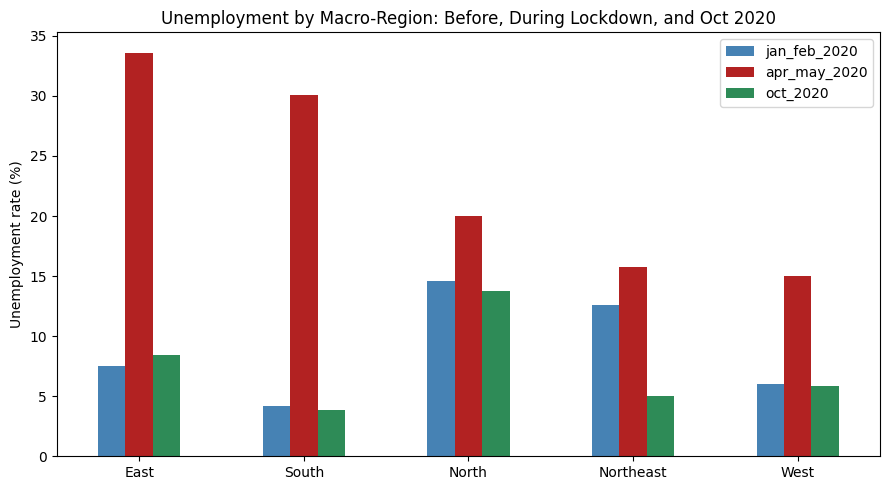

In [24]:
ax = macro.set_index("macro_region")[["jan_feb_2020", "apr_may_2020", "oct_2020"]].plot(
    kind="bar", figsize=(9, 5), color=["steelblue", "firebrick", "seagreen"])
ax.set_title("Unemployment by Macro-Region: Before, During Lockdown, and Oct 2020")
ax.set_ylabel("Unemployment rate (%)")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Finding:** between Jan-Feb and Apr-May 2020 the East went from 7.5% to 33.6% and the South from 4.2% to 30.1%. The North had the highest baseline (14.6%) but a smaller jump (to 20.0%). By October 2020 every macro-region was back near or below its starting level.

## 8. Seasonality: what the data can and cannot say

The first file has only about 10 months before the shock (May 2019 - Feb 2020), with a mild upward drift from about 8.9% to 10%. With less than one full year of pre-Covid data, **no seasonal pattern can be reliably identified**. A seasonal claim would need at least 2-3 years of monthly data.

## 9. Policy implications (based on the findings above)

- Urban informal workers need faster income support during lockdowns, since unemployment rose most in urban areas.
- Support should be targeted by state, not uniform: a few states account for the most extreme increases.
- The quick recovery suggests the shock was tied mainly to the lockdown itself, so reopening plans matter as much as relief schemes.

## 10. Limitations

- Averages are simple means of state-level rates, not an official national rate; large and small states count equally.
- Rows per month vary slightly (50-54) because some state/area series have missing months. Chandigarh has no data for Apr-May 2020.
- The two files overlap in Jan-Jun 2020 but cover different rows (the second has no rural/urban split), so they are not merged into one series.
- Extreme values such as Puducherry's 75% come straight from the source and were not altered.
- This is descriptive analysis: it shows what happened, not what caused it.